In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

DATA_DIR = r"C:\Users\minsa_\Downloads"     # folder with Cleaned_Dataset.csv and Final_Features.csv

clean = pd.read_csv(os.path.join(DATA_DIR, "Cleaned_Dataset.csv"))
final = pd.read_csv(os.path.join(DATA_DIR, "Final_Features.csv"))
print("Cleaned_Dataset:", clean.shape, "| Final_Features:", final.shape)

Cleaned_Dataset: (1048, 31) | Final_Features: (1048, 11)


In [2]:
df = final.merge(clean[["Tissue_ID", "Disease_Label"]], on="Tissue_ID", how="left")
print("Rows:", len(df), "| missing Disease_Label:", df["Disease_Label"].isna().sum())
df["Disease_Label"].value_counts().to_frame("Count")

Rows: 1048 | missing Disease_Label: 0


,Count
Disease_Label,
Normal,504
Folds,324
FECD; Polymorphism and pleomorphism; Low cell density,88
Guttata,53
Guttata; Folds,28
FECD; Polymorphism and pleomorphism; Low cell density; Folds,20
FECD; Polymorphism and pleomorphism; Low cell density; Guttata,8
Polymorphism and pleomorphism,5
Folds; Guttata,3


In [3]:
LABELS = {
    "FECD": "FECD",
    "Guttata": "Guttata",
    "Folds": "Folds",
    "PolyPleo": "Polymorphism and pleomorphism",
    "LowCD": "Low cell density",
}
for col, text in LABELS.items():
    df[col] = df["Disease_Label"].str.contains(text, case=False, regex=False).astype(int)

LABEL_COLS = list(LABELS.keys())
df["n_Diseases"] = df[LABEL_COLS].sum(axis=1)
df["Normal"] = (df["n_Diseases"] == 0).astype(int)

# safety check: every non-Normal label must have at least one disease
bad = df[(df["Normal"] == 1) & (df["Disease_Label"] != "Normal")]
print("Rows with no disease found but label is not 'Normal':", len(bad))
display(bad[["Tissue_ID", "Disease_Label"]])

# one example row per original label, to check the conversion by eye
df[["Disease_Label"] + LABEL_COLS + ["Normal"]].drop_duplicates("Disease_Label").reset_index(drop=True)

Rows with no disease found but label is not 'Normal': 0


,Tissue_ID,Disease_Label


,Disease_Label,FECD,Guttata,Folds,PolyPleo,LowCD,Normal
0,Normal,0,0,0,0,0,1
1,Folds,0,0,1,0,0,0
2,FECD; Polymorphism and pleomorphism; Low cell ...,1,0,0,1,1,0
3,FECD; Polymorphism and pleomorphism; Low cell ...,1,1,0,1,1,0
4,Guttata; Folds,0,1,1,0,0,0
5,Folds; Guttata,0,1,1,0,0,0
6,Guttata,0,1,0,0,0,0
7,FECD; Polymorphism and pleomorphism; Low cell ...,1,0,1,1,1,0
8,FECD; Polymorphism and pleomorphism; Low cell ...,1,1,1,1,1,0
9,Folds; FECD; Polymorphism and pleomorphism; Lo...,1,0,1,1,1,0


In [4]:
summary = pd.DataFrame({
    "Total": df[LABEL_COLS + ["Normal"]].sum(),
    "Train": df.loc[df["Split"] == "train", LABEL_COLS + ["Normal"]].sum(),
    "Test":  df.loc[df["Split"] == "test",  LABEL_COLS + ["Normal"]].sum(),
})
summary["% of corneas"] = (summary["Total"] / len(df) * 100).round(1)
display(summary)

print("Number of diseases per cornea:")
df["n_Diseases"].value_counts().sort_index().to_frame("Corneas")

,Total,Train,Test,% of corneas
FECD,127,102,25,12.1
Guttata,100,81,19,9.5
Folds,380,306,74,36.3
PolyPleo,132,106,26,12.6
LowCD,126,103,23,12.0
Normal,504,403,101,48.1


Number of diseases per cornea:


,Corneas
n_Diseases,
0,504
1,385
2,34
3,91
4,31
5,3


In [5]:
def combo_name(r):
    found = [c for c in LABEL_COLS if r[c] == 1]
    return " + ".join(found) if found else "Normal"

df["Combination"] = df.apply(combo_name, axis=1)
combos = df.groupby("Combination").agg(Total=("Tissue_ID", "size"),
                                       Train=("Split", lambda s: (s == "train").sum()),
                                       Test=("Split", lambda s: (s == "test").sum()))
combos.sort_values("Total", ascending=False)

,Total,Train,Test
Combination,,,
Normal,504,403,101
Folds,324,259,65
FECD + PolyPleo + LowCD,89,71,18
Guttata,53,42,11
Guttata + Folds,31,25,6
FECD + Folds + PolyPleo + LowCD,21,18,3
FECD + Guttata + PolyPleo + LowCD,10,9,1
PolyPleo,5,4,1
FECD + Guttata + Folds + PolyPleo + LowCD,3,3,0


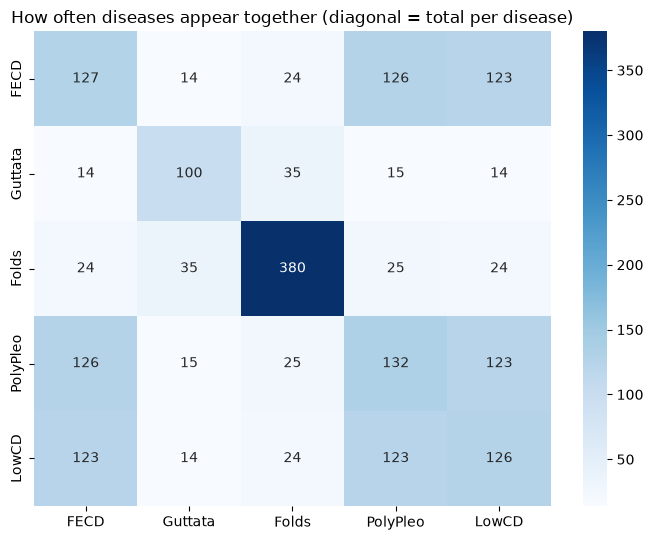

Row disease present -> % that also have the column disease:


,FECD,Guttata,Folds,PolyPleo,LowCD
FECD,100.0,11.0,19.0,99.0,97.0
Guttata,14.0,100.0,35.0,15.0,14.0
Folds,6.0,9.0,100.0,7.0,6.0
PolyPleo,95.0,11.0,19.0,100.0,93.0
LowCD,98.0,11.0,19.0,98.0,100.0


In [6]:
co = df[LABEL_COLS].T.dot(df[LABEL_COLS])
plt.figure(figsize=(7, 5.5))
sns.heatmap(co, annot=True, fmt="d", cmap="Blues")
plt.title("How often diseases appear together (diagonal = total per disease)")
plt.tight_layout(); plt.show()

cond = (co / np.diag(co)[:, None] * 100).round(0)
print("Row disease present -> % that also have the column disease:")
cond

In [7]:
for col in ["PolyPleo", "LowCD", "Guttata", "Folds"]:
    alone = (df[col] == 1) & (df["FECD"] == 0)
    print(f"{col:9s} without FECD: {alone.sum():4d}  (of {df[col].sum()})")

print("\nFECD without PolyPleo or LowCD:",
      ((df["FECD"] == 1) & (df["PolyPleo"] == 0) & (df["LowCD"] == 0)).sum())

PolyPleo  without FECD:    6  (of 132)
LowCD     without FECD:    3  (of 126)
Guttata   without FECD:   86  (of 100)
Folds     without FECD:  356  (of 380)

FECD without PolyPleo or LowCD: 1


In [8]:
df["Target_Severity"] = df["Target_Severity"].fillna("None")
out_cols = (["Tissue_ID", "Donor_Group", "Split", "Disease_Label"]
            + LABEL_COLS + ["Normal", "n_Diseases", "Combination", "Target_Severity"]
            + ["ECD_CD_cells_per_mm2", "ECD_Deficit", "SD", "CV", "HEX_percent", "Donor_Age"])

df[out_cols].to_csv(os.path.join(DATA_DIR, "Final_Features_MultiLabel.csv"), index=False)
print("Saved Final_Features_MultiLabel.csv", df[out_cols].shape)

Saved Final_Features_MultiLabel.csv (1048, 19)
